# E-DAC Learning Effect: Learned vs No-Learning Baseline

Compares two E-DAC equipment-cost bases used in this study's LCOR calculation
($\mathrm{LCOR} = (C_\mathrm{cap} + C_\mathrm{op})/R$, `src.costs.edac_equipment_costs`):

- **Learned (2050)** -- this study's central assumption: `A.EDAC.LearnedCapexPerAnnualCaptureCapacity` /
  `LearnedFixedOpexPerAnnualCaptureCapacity`, scaled down from the reference-plant cost by a
  Wright's-law experience curve, $C(N) = C_0 (N/N_0)^b$ with $b = \log_2(1-LR)$, evaluated at an
  assumed 2050 global cumulative deployment (`A.EDAC.CumulativeDeployment = 9.0e6 t`,
  approx 197x the reference deployment `N_0`).
- **No-learning baseline** -- the unscaled reference-plant cost from Leonzio & Shah (2025)
  (`A.EDAC.CapexPerAnnualCaptureCapacity`), i.e. the special case $N = N_0$ (deployment ratio = 1).

Both are compared on the same basis: GBP, equipment-only cost (annualised CAPEX + fixed OPEX;
excludes electricity, labour, sorbent, transport and CO2 storage), at the two E-DAC discount-rate
scenarios (`CentralDiscountRate` = 5%, `SensitivityDiscountRate` = 10%).

**Data-quality note**: the 14%/2.5% learning rates and the 9.0 Mt cumulative-deployment assumption
are undocumented in `src/assumptions.py` ("team assumption, TBC") -- no literature source was found
anywhere in the repo for either figure. `nbs/edac_lcor_sensitivity.ipynb`'s footnote is also stale:
it prints the *current* (~197x) deployment ratio while simultaneously mislabelling it
"(inactive, currently = reference deployment)".

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

import src.assumptions as A
import src.matplotlib_style  # noqa: F401
from src.costs import edac_equipment_costs
from src.units import Units as U
from src.utils import annualised_cost


In [2]:
# Palette, layered on top of src.matplotlib_style's defaults
# (matches the palette used in nbs/edac_lcor_sensitivity.ipynb for visual consistency).
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"  # Learned (2050)
ORANGE = "#eb6834"  # No-learning baseline

plt.rcParams.update(
    {
        "figure.figsize": (7.5, 5.2),
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.grid": False,
        "text.color": INK_PRIMARY,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "grid.color": GRID,
        "grid.linewidth": 1,
        "axes.unicode_minus": False,
        "font.size": 11,
    }
)


def style_axes(ax: plt.Axes, *, grid: bool = True) -> None:
    """Apply the shared hairline/recessive-grid look to an axes."""
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(AXIS)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(length=0)
    if grid:
        ax.grid(axis="y", linewidth=1, color=GRID)
        ax.set_axisbelow(True)


In [3]:
REFERENCE_INSTALLED_POWER = 1 * U.GW  # arbitrary: LCOR is independent of installed power
                                        # (CAPEX, OPEX and removals all scale with it linearly)


def nameplate_removals(installed_power):
    """Full-load annual CO2 removal capacity implied by an installed E-DAC power."""
    nameplate_energy = (installed_power * A.HoursPerYear).to(U.TWh)
    return (nameplate_energy / A.DAC.EnergyCost.MediumTWhPerMtCO2).to(U.t)


def edac_lcor(capex_per_capacity, opex_per_capacity, capacity_factor, discount_rate, installed_power=REFERENCE_INSTALLED_POWER):
    """Equipment-only LCOR for arbitrary CAPEX/OPEX-per-capacity inputs.

    Replicates src.costs.edac_equipment_costs's internal formula exactly, but takes
    the CAPEX/OPEX-per-capacity as parameters so both the learned and no-learning
    cases can be computed and compared without modifying src/.
    """
    removals = nameplate_removals(installed_power)
    actual_removals = removals * capacity_factor
    total_capex = (removals * capex_per_capacity).to(U.GBP)
    annualised_capex = annualised_cost(total_capex, 0 * U.GBP, A.EDAC.Lifetime, discount_rate)
    fixed_opex = (removals * opex_per_capacity).to(U.GBP)
    annual_cost = annualised_capex + fixed_opex
    if actual_removals.magnitude <= 0:
        return float("inf")
    return (annual_cost / actual_removals).to(U.GBP / U.t).magnitude


LEARNED_CAPEX = A.EDAC.LearnedCapexPerAnnualCaptureCapacity
LEARNED_OPEX = A.EDAC.LearnedFixedOpexPerAnnualCaptureCapacity
NO_LEARNING_CAPEX = A.EDAC.CapexPerAnnualCaptureCapacity  # deployment ratio = 1: Leonzio & Shah (2025)'s raw reference cost
NO_LEARNING_OPEX = A.EDAC.FixedOpexFraction * A.EDAC.CapexPerAnnualCaptureCapacity

# Correctness check: edac_lcor() with the Learned* constants must reproduce
# src.costs.edac_equipment_costs exactly (same formula, just parameterised).
_check_power = 2 * U.GW
_check_cf = 0.4
_check_removals = nameplate_removals(_check_power) * _check_cf
_reference = edac_equipment_costs(_check_power, _check_removals)["lcor"].to(U.GBP / U.t).magnitude
_ours = edac_lcor(LEARNED_CAPEX, LEARNED_OPEX, _check_cf, A.EDAC.CentralDiscountRate, _check_power)
assert abs(_reference - _ours) < 1e-6, f"Mismatch: {_reference} vs {_ours}"
print(f"Correctness check passed: edac_lcor() matches edac_equipment_costs() ({_ours:.4f} GBP/t)")
print(f"Deployment ratio (learned vs no-learning): {A.EDAC.DeploymentRatio:.1f}x reference deployment")
print(f"Learned CAPEX:      {LEARNED_CAPEX.to(U.GBP / U.t):.1f}   (vs no-learning {NO_LEARNING_CAPEX.to(U.GBP / U.t):.1f})")
print(f"Learned fixed OPEX: {LEARNED_OPEX.to(U.GBP / U.t):.1f}   (vs no-learning {NO_LEARNING_OPEX.to(U.GBP / U.t):.1f})")


Correctness check passed: edac_lcor() matches edac_equipment_costs() (57.9353 GBP/t)
Deployment ratio (learned vs no-learning): 197.4x reference deployment
Learned CAPEX:      159.5 GBP / ton   (vs no-learning 503.6 GBP / ton)
Learned fixed OPEX: 10.4 GBP / ton   (vs no-learning 12.6 GBP / ton)


## LCOR vs capacity factor: Learned vs No-Learning Baseline

Sweeps capacity factor from 5% to 100% at both E-DAC discount-rate scenarios. This is the
"output graph" for inspection before any of these numbers go into the paper.

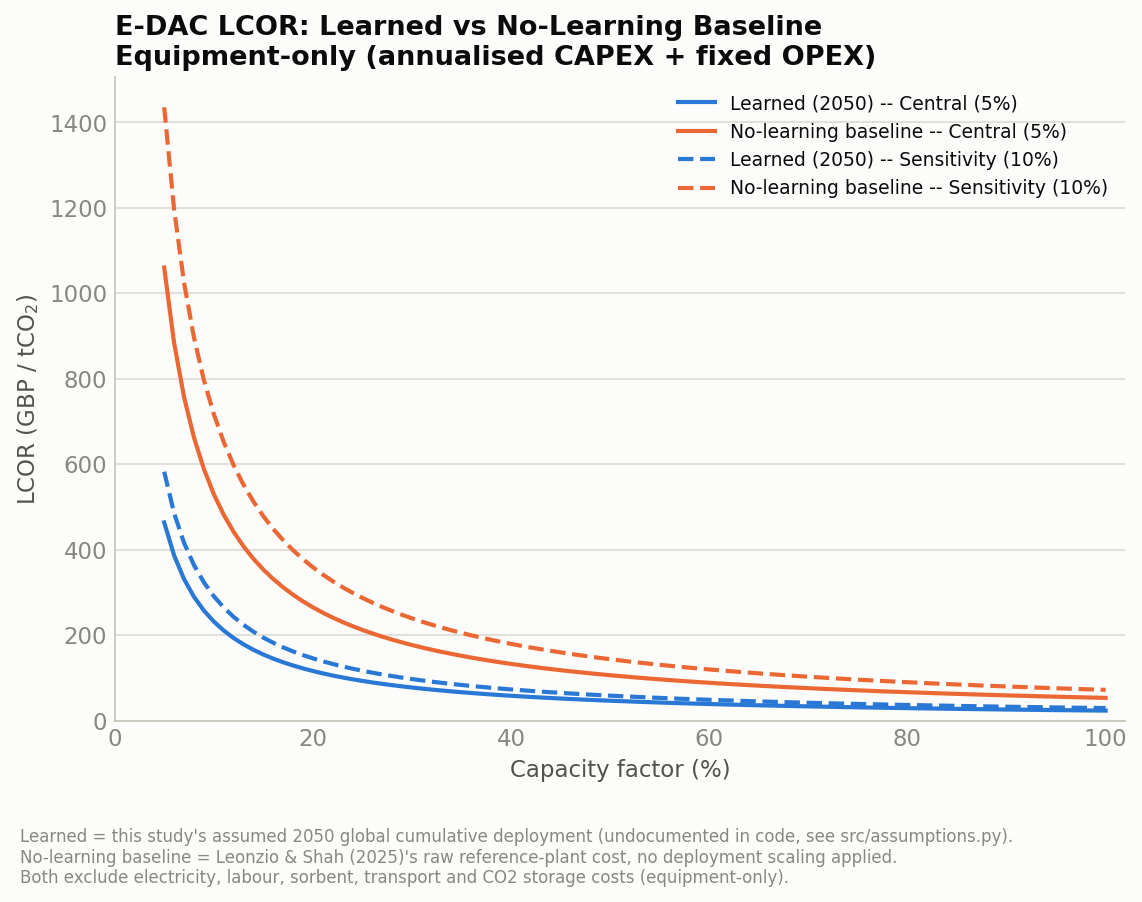

In [4]:
capacity_factors = np.linspace(0.05, 1.0, 96)
discount_rate_scenarios = {
    "Central (5%)": (A.EDAC.CentralDiscountRate, "-"),
    "Sensitivity (10%)": (A.EDAC.SensitivityDiscountRate, "--"),
}

fig, ax = plt.subplots()
for label, (dr, ls) in discount_rate_scenarios.items():
    learned = [edac_lcor(LEARNED_CAPEX, LEARNED_OPEX, cf, dr) for cf in capacity_factors]
    baseline = [edac_lcor(NO_LEARNING_CAPEX, NO_LEARNING_OPEX, cf, dr) for cf in capacity_factors]
    ax.plot(capacity_factors * 100, learned, color=BLUE, linestyle=ls, linewidth=2, label=f"Learned (2050) -- {label}")
    ax.plot(capacity_factors * 100, baseline, color=ORANGE, linestyle=ls, linewidth=2, label=f"No-learning baseline -- {label}")

style_axes(ax)
ax.set_xlabel("Capacity factor (%)")
ax.set_ylabel("LCOR (GBP / tCO$_2$)")
ax.set_xlim(0, 102)
ax.set_ylim(0, None)
ax.set_title(
    "E-DAC LCOR: Learned vs No-Learning Baseline\nEquipment-only (annualised CAPEX + fixed OPEX)",
    loc="left", fontsize=13, fontweight="bold",
)
ax.legend(frameon=False, fontsize=9, loc="upper right")
fig.text(
    0.01, -0.05,
    "Learned = this study's assumed 2050 global cumulative deployment (undocumented in code, see src/assumptions.py).\n"
    "No-learning baseline = Leonzio & Shah (2025)'s raw reference-plant cost, no deployment scaling applied.\n"
    "Both exclude electricity, labour, sorbent, transport and CO2 storage costs (equipment-only).",
    ha="left", va="top", fontsize=8, color=INK_MUTED,
)
plt.show()


## Reference point: a real simulated scenario

Rather than assuming a capacity factor, this runs one representative `PowerSystem` scenario
(same defaults as `nbs/no_h2_power_system_demo.ipynb`'s no-imports case) to get an actual
model-simulated E-DAC capacity factor, then reads the learned vs no-learning LCOR off the
curves above at that point.

In [5]:
from src.data import renewable_capacity_factors
from src.demand_model import DemandMode, predicted_demand
from src.power_system import PowerSystem
from src.supply_model import daily_renewables_capacity

# One representative scenario, to get a real model-simulated E-DAC capacity factor
# rather than an assumed/invented one.
_renewable_capacity = 200 * U.GW
_dac_capacity = 2 * U.GW

_demand_df = predicted_demand(mode=DemandMode.SEASONAL, historical="era5", filter_ldz=True)
_daily_cf = renewable_capacity_factors.get_renewable_capacity_factors(source="era5_2024", resample="D")
_supply = daily_renewables_capacity(_renewable_capacity, _daily_cf)
_common_idx = _supply.index.intersection(_demand_df.index)
_net_supply_df = (_supply.reindex(_common_idx) - _demand_df["demand"].reindex(_common_idx)).to_frame(
    name=f"S-D(TWh),Ren={_renewable_capacity.magnitude}GW"
)

_ps = PowerSystem(
    renewable_capacity=_renewable_capacity,
    hydrogen_storage_capacity=A.HydrogenStorage.CavernStorage.Capacity,
    electrolyser_power=A.HydrogenStorage.Electrolysis.Power,
    dac_capacity=_dac_capacity,
)
_sim_df = _ps.run_simulation(_net_supply_df)
assert _sim_df is not None, "Simulation failed (storage exhausted) -- adjust scenario inputs"
_results = _ps.analyze_simulation_results(_sim_df)
simulated_cf = _results["dac_capacity_factor"]

print(f"Representative scenario: renewable_capacity={_renewable_capacity}, dac_capacity={_dac_capacity}")
print(f"Simulated E-DAC capacity factor: {simulated_cf:.1%}\n")

print(f"{'Case':<22}{'Central (5%)':>16}{'Sensitivity (10%)':>20}")
for name, (capex, opex) in [
    ("Learned (2050)", (LEARNED_CAPEX, LEARNED_OPEX)),
    ("No-learning baseline", (NO_LEARNING_CAPEX, NO_LEARNING_OPEX)),
]:
    row = [edac_lcor(capex, opex, simulated_cf, dr) for dr, _ in discount_rate_scenarios.values()]
    print(f"{name:<22}{row[0]:>13.1f} \u00a3/t{row[1]:>17.1f} \u00a3/t")


Representative scenario: renewable_capacity=200 gigawatt, dac_capacity=2 gigawatt
Simulated E-DAC capacity factor: 30.4%

Case                      Central (5%)   Sensitivity (10%)
Learned (2050)                 76.1 £/t             95.6 £/t
No-learning baseline          174.1 £/t            235.7 £/t
